In [1]:
# Image Forgery Detection
# This notebook implements a patch-based deep learning approach to detect
# and localize image manipulations (splicing/forgery) by analyzing JPEG compression artifacts.

In [2]:
# Install jpegio to read low-level JPEG data (DCT coefficients and quantization tables)
!pip install jpegio

import os
import torch
import cv2
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import jpegio as jio
import matplotlib.pyplot as plt
from tqdm import tqdm # For progress bar visualization
from scipy.ndimage import gaussian_filter # For smoothing the final forgery heatmap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 MB 9.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for jpegio: filename=jpegio-0.2.8-cp312-cp312-linux_x86_64.whl size=1277309 sha256=cc95d153d447683b29815be693ff654a6b16e1114e6dd605697b69609fa35a66
  Stored in directory: /root/.cache/pip/wheels/4e/5f/d9/3898c36bd7e9166a13a514d61f7ddd7310c192bfb443e758f8
Successfully built jpegio


In [3]:
# Device setup: Automatically use GPU (CUDA) for faster inference if available, otherwise fallback to CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


In [4]:
# ── Your exact DenseLayer ──────────────────────────────────────
# A single building block of the DenseNet architecture.
class DenseLayer(nn.Module):
    def __init__(self, in_ch, k):
        super().__init__()
        # The bottleneck architecture: 1x1 conv followed by 3x3 conv
        # This reduces computation while allowing deep feature extraction
        self.net = nn.Sequential(
            nn.BatchNorm2d(in_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_ch, 4*k, 1, bias=False), # Bottleneck layer
            nn.BatchNorm2d(4*k),
            nn.ReLU(inplace=True),
            nn.Conv2d(4*k, k, 3, padding=1, bias=False) # Spatial convolution
        )

    def forward(self, x):
        # The core idea of DenseNet: concatenate the input features with the new output features
        # This solves the vanishing gradient problem and encourages feature reuse
        return torch.cat([x, self.net(x)], 1)

In [5]:
# A modified DenseNet-121 model tailored for 2-channel input (Histogram + Quantization tables)
class DenseNet121_JPEG(nn.Module):
    def __init__(self, num_classes=2, k=32):
        super().__init__()

        # Stem: Initial convolution block that processes the input image features
        # Notice in_channels=2 because the input X has 2 channels (H_matrix and Q_prime)
        self.stem = nn.Sequential(
            nn.Conv2d(2, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1)
        )

        in_ch = 64
        # Standard DenseNet-121 block configuration: 6, 12, 24, and 16 layers per block
        config = [6, 12, 24, 16]
        self.blocks = nn.ModuleList()

        for i, nl in enumerate(config):
            # Create a Dense Block consisting of 'nl' Dense Layers
            block = nn.Sequential(
                *[DenseLayer(in_ch + j*k, k) for j in range(nl)]
            )
            self.blocks.append(block)
            in_ch += nl * k # Update channel count after concatenation

            # Add Transition Layers between Dense Blocks (except after the last block)
            # These downsample the feature maps using 1x1 conv and 2x2 pooling
            if i < 3:
                trans = nn.Sequential(
                    nn.BatchNorm2d(in_ch),
                    nn.ReLU(inplace=True),
                    nn.Conv2d(in_ch, in_ch//2, 1, bias=False), # Compress channels by half
                    nn.AvgPool2d(2, stride=2)                  # Halve spatial dimensions
                )
                self.blocks.append(trans)
                in_ch //= 2

        self.final_bn = nn.BatchNorm2d(in_ch)
        self.classifier = nn.Linear(in_ch, num_classes) # Final dense layer for binary classification

    def forward(self, x):
        x = self.stem(x)
        for b in self.blocks:
            x = b(x)
        x = F.relu(self.final_bn(x))
        # Global Average Pooling flattens the spatial dimensions before classification
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.classifier(x)

In [6]:
# Extracts statistical features from JPEG Discrete Cosine Transform (DCT) coefficients.
# This reveals double-compression artifacts typically left behind when an image is forged.
def jpeg_to_X_full(path, y, x, b=100):
    try:
        # Read the raw JPEG structure (DCT arrays and Quantization tables)
        jpg = jio.read(str(path))

        # Extract a 256x256 patch of DCT coefficients corresponding to the spatial location
        dct = jpg.coef_arrays[0][y:y+256, x:x+256]

        # Extract the luma quantization table (8x8 matrix)
        q = jpg.quant_tables[0].reshape(8,8) \
            if jpg.quant_tables[0].ndim == 1 \
            else jpg.quant_tables[0]

        # Ensure the patch is exactly 256x256; discard edges that don't fit
        if dct.shape != (256, 256):
            return None

        # Setup bins for the histogram mapping (-100 to 100)
        bins = np.arange(-b, b+2) - 0.5

        # Matrices to hold our 2-channel input features
        H_matrix = np.zeros((64, 2*b+1), dtype=np.float32) # Histogram of DCT modes
        Q_prime  = np.zeros((64, 2*b+1), dtype=np.float32) # Quantization steps

        # Loop over the 64 (8x8) DCT frequencies
        for idx, (u, v) in enumerate((u,v) for u in range(8) for v in range(8)):
            # Flatten and clip the coefficients for this specific frequency to [-100, 100]
            c = np.clip(dct[u::8, v::8].flatten(), -b, b)

            # Channel 1: Compute histogram of coefficients for this DCT mode
            H_matrix[idx], _ = np.histogram(c, bins=bins)

            # Channel 2: Fill the second channel with the corresponding quantization step
            Q_prime[idx] = float(q[u, v])

        # Stack channels to shape (64, 201, 2)
        X = np.stack([H_matrix, Q_prime], axis=-1)

        # Normalize the input tensor
        X /= (X.max() + 1e-6)
        return X
    except:
        return None

In [7]:
import os
import cv2

image_path = '/content/finaltest1.jpg'

# Pre-check to ensure the image exists and can be read by OpenCV
if not os.path.exists(image_path):
    print(f" Error: Image file '{image_path}' not found")
else:
    img = cv2.imread(image_path)
    if img is None:
        print("CV2 error")
    else:
        print(f"Image loaded! Size: {img.shape}")

model_path = '/content/best_model.pth'

# Pre-check to ensure the pre-trained weights file exists and isn't corrupted
if os.path.exists(model_path):
    size = os.path.getsize(model_path) / (1024 * 1024)
    print(f" Model File Size: {size:.2f} MB")
    if size < 1:
        print("Corrupt model file")
else:
    print("Model file not found")

Image loaded! Size: (1333, 1000, 3)
 Model File Size: 48.00 MB


In [8]:
B = 100  # Boundary for DCT coefficient clipping

# ── detect_forgery ─────────────────────────────────────────────
def detect_forgery(
    image_path,
    model_path,
    patch_size=128,
    stride=32,
    sigma=2,
    threshold_ratio=0.65
):

    # ------------------------------------------------------------
    # Load model
    # ------------------------------------------------------------
    model = DenseNet121_JPEG().to(DEVICE)

    ckpt = torch.load(model_path, map_location=DEVICE)

    if isinstance(ckpt, dict) and 'model_state_dict' in ckpt:
        model.load_state_dict(ckpt['model_state_dict'])
    else:
        model.load_state_dict(ckpt)

    model.eval()

    print("Model loaded")

    # ------------------------------------------------------------
    # Load image
    # ------------------------------------------------------------
    img = cv2.imread(image_path)

    if img is None:
        raise ValueError(f"Could not load image: {image_path}")

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    print(f"Image size: {w} × {h}")

    # ------------------------------------------------------------
    # Heatmap containers
    # ------------------------------------------------------------
    heatmap = np.zeros((h, w), dtype=np.float32)
    counts  = np.zeros((h, w), dtype=np.float32)

    # ------------------------------------------------------------
    # Gaussian weighting window
    # Strong center voting -> sharper localization
    # ------------------------------------------------------------
    g1d = cv2.getGaussianKernel(patch_size, patch_size / 6)

    gaussian_window = g1d @ g1d.T

    gaussian_window = gaussian_window / gaussian_window.max()

    # ------------------------------------------------------------
    # Total patches
    # ------------------------------------------------------------
    total = (
        ((h - patch_size) // stride) + 1
    ) * (
        ((w - patch_size) // stride) + 1
    )

    print(f"Scanning {total} patches...")

    # ------------------------------------------------------------
    # Sliding window inference
    # ------------------------------------------------------------
    for y in tqdm(range(0, h - patch_size + 1, stride)):
        for x in range(0, w - patch_size + 1, stride):

            # ----------------------------------------------------
            # Feature extraction
            # ----------------------------------------------------
            X = jpeg_to_X_full(image_path, y, x, b=B)

            if X is None:
                continue

            # ----------------------------------------------------
            # Tensor conversion
            # ----------------------------------------------------
            Xt = (
                torch.tensor(X)
                .permute(2, 0, 1)
                .unsqueeze(0)
                .float()
                .to(DEVICE)
            )

            # ----------------------------------------------------
            # Inference
            # ----------------------------------------------------
            with torch.no_grad():

                logits = model(Xt)

                probs = F.softmax(logits, dim=1).cpu().numpy()[0]

            forged_score = probs[1]

            # ----------------------------------------------------
            # Weighted voting
            # ----------------------------------------------------
            weighted_vote = gaussian_window * forged_score

            heatmap[
                y:y + patch_size,
                x:x + patch_size
            ] += weighted_vote

            counts[
                y:y + patch_size,
                x:x + patch_size
            ] += gaussian_window

    # ------------------------------------------------------------
    # Normalize overlap regions
    # ------------------------------------------------------------
    heatmap /= np.maximum(counts, 1e-7)

    # ------------------------------------------------------------
    # Light smoothing only
    # ------------------------------------------------------------
    smooth = gaussian_filter(heatmap, sigma=sigma)

    # ------------------------------------------------------------
    # Normalize to [0,1]
    # ------------------------------------------------------------
    norm = (
        smooth - smooth.min()
    ) / (
        smooth.max() - smooth.min() + 1e-7
    )

    # ------------------------------------------------------------
    # Manual threshold
    # Better than Otsu for forgery maps
    # ------------------------------------------------------------
    threshold_value = threshold_ratio * norm.max()

    mask = (norm > threshold_value).astype(np.uint8) * 255

    # ------------------------------------------------------------
    # Morphological cleanup
    # ------------------------------------------------------------
    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # ------------------------------------------------------------
    # Keep largest connected component
    # ------------------------------------------------------------
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask)

    if num_labels > 1:

        largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )

        final_mask = np.zeros_like(mask)

        final_mask[labels == largest] = 255

        mask = final_mask

    # ------------------------------------------------------------
    # Forged area percentage
    # ------------------------------------------------------------
    forged_percent = (mask > 0).mean() * 100

    print(f"Forged area: {forged_percent:.2f}%")

    # ------------------------------------------------------------
    # Visualization
    # ------------------------------------------------------------
    plt.figure(figsize=(18, 6))

    # Original image
    plt.subplot(131)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis("off")

    # Heatmap
    plt.subplot(132)
    plt.imshow(norm, cmap='jet')
    plt.title("Inconsistency Heatmap")
    plt.axis("off")

    # Final mask
    plt.subplot(133)
    plt.imshow(mask, cmap='gray')
    plt.title("Final Forgery Mask")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        '/content/forgery_result.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

    return mask

Model loaded
Image size: 1000 × 1333
Scanning 1064 patches...


100%|██████████| 38/38 [01:36<00:00,  2.54s/it]


Forged area: 1.47%


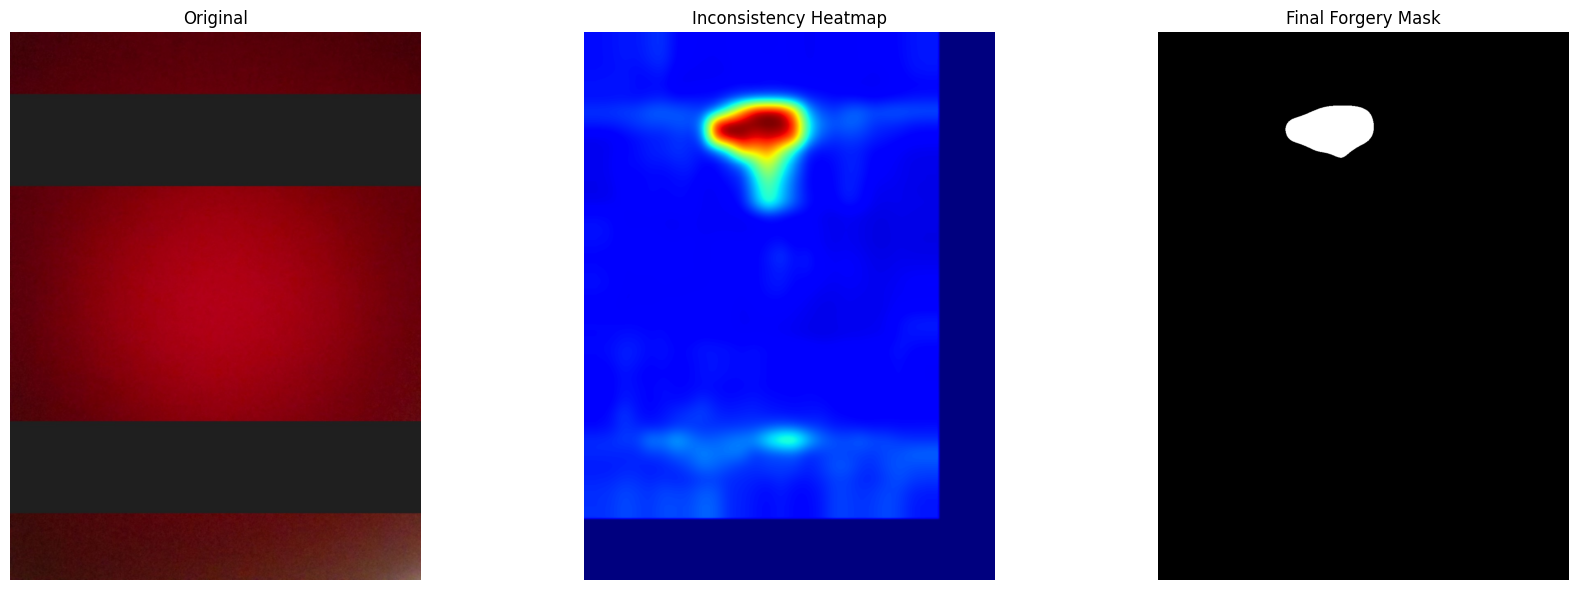

In [12]:
# # Define paths and execute the main pipeline
# MODEL_PATH = '/content/best_model.pth'  # Path to pre-trained weights
# IMAGE_PATH = '/content/finaltest1.jpg'         # Target image to analyze

# Run the detection function
mask = detect_forgery(
    image_path="/content/finaltest1.jpg",
    model_path="/content/best_model.pth",
    patch_size=128,
    stride=32,
    sigma=2,
    threshold_ratio=0.65
)